# 02 · 因果自注意力：QKV 与遮罩可视化

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 因果自注意力

对应 `model.py/CausalSelfAttention`：线性映射同时生成 Q/K/V，按 head 分组，计算 $\mathrm{softmax}(QK^T/\sqrt{d_k} + M)V$。其中上三角未来位置的 mask 为负无穷。这里用**手工矩阵**绘图核验，再与 `scaled_dot_product_attention(..., is_causal=True)` 比较。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


Q/K/V shape: (1, 2, 10, 8) scores shape: (1, 2, 10, 10) weights: (1, 2, 10, 10)
Head 0 / position 4 attention: [0.39100000262260437, 0.08100000023841858, 0.1340000033378601, 0.3610000014305115, 0.032999999821186066, 0.0, 0.0, 0.0, 0.0, 0.0]
Max attention on future tokens: 0.0


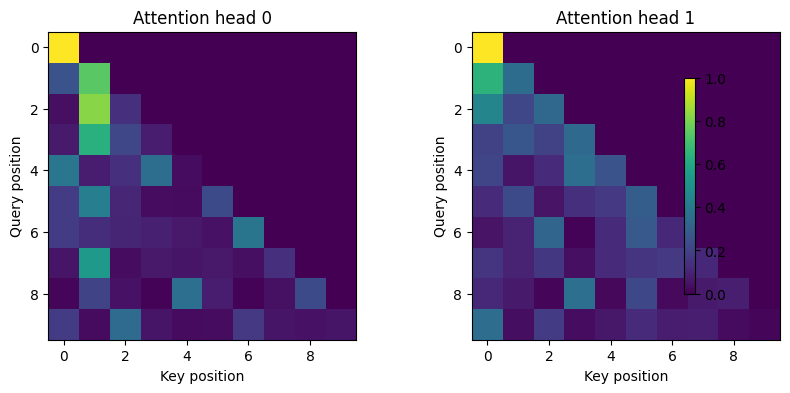

In [2]:
import torch.nn.functional as F
B, H, T, D = 1, 2, 10, 8
q=torch.randn(B,H,T,D);k=torch.randn(B,H,T,D);v=torch.randn(B,H,T,D)
scores=(q @ k.transpose(-2,-1)) / (D**0.5)
mask=torch.tril(torch.ones(T,T,dtype=torch.bool))
weights=torch.softmax(scores.masked_fill(~mask, float('-inf')), dim=-1)
print('Q/K/V shape:',tuple(q.shape),'scores shape:',tuple(scores.shape),'weights:',tuple(weights.shape))
print('Head 0 / position 4 attention:',weights[0,0,4].round(decimals=3).tolist())
print('Max attention on future tokens:',float(weights.masked_select((~mask).expand(B,H,T,T)).abs().max()))
assert torch.all(weights.masked_select((~mask).expand(B,H,T,T)) == 0)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for h,ax in enumerate(axes):
    im=ax.imshow(weights[0,h].numpy(),vmin=0,vmax=1,cmap='viridis');ax.set_title(f'Attention head {h}')
    ax.set_xlabel('Key position');ax.set_ylabel('Query position')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.7);fig.subplots_adjust(wspace=.28,right=.88)
fig.savefig(FIG / '02_attention_weights.png', dpi=130); display(fig); plt.close(fig)

manual output: (1, 2, 10, 8) SDPA output: (1, 2, 10, 8)
Maximum absolute implementation difference: 2.384185791015625e-07


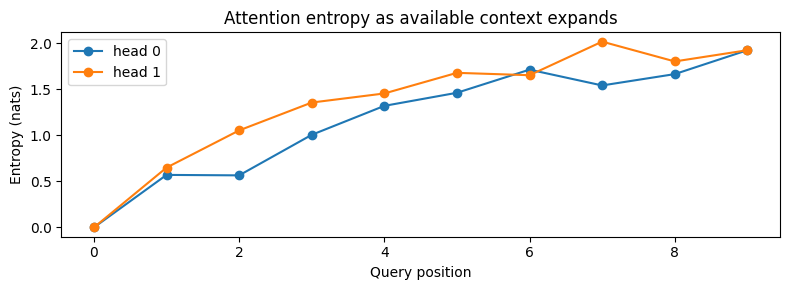

In [3]:
y_manual=weights @ v
y_sdpa=F.scaled_dot_product_attention(q,k,v,is_causal=True,dropout_p=0.0)
delta=(y_manual-y_sdpa).abs().max().item()
print('manual output:',tuple(y_manual.shape),'SDPA output:',tuple(y_sdpa.shape))
print('Maximum absolute implementation difference:',delta)
assert torch.allclose(y_manual,y_sdpa,atol=1e-5)
all_entropy=-(weights*torch.log(weights.clamp_min(1e-12))).sum(-1).squeeze(0)
fig,ax=plt.subplots(figsize=(8,3));ax.plot(range(T),all_entropy[0],marker='o',label='head 0');ax.plot(range(T),all_entropy[1],marker='o',label='head 1')
ax.set_title('Attention entropy as available context expands'); ax.set_xlabel('Query position');ax.set_ylabel('Entropy (nats)');ax.legend();fig.tight_layout()
fig.savefig(FIG / '02_attention_entropy.png', dpi=130); display(fig); plt.close(fig)

### 思考

为什么 `t=0` 的注意力熵为 0？`is_causal=True` 如何阻止未来信息泄漏？注意：PyTorch **SDPA API** 会自动选择实现，不能因为使用此函数就声称本 CPU 运行启用了 GPU Flash Attention。